# **Final Year Project - Year 4 Software Development**
## Iteration 2 - Onset Detection Refinement

*By Mark Lambert - C00192497*

*3/11/2026*

---

This notebook aims to refine the onset detection algorithm to be more precise. The logic from `get_chords()` in `../fretwave/chord_detect.py` is extracted and analysed

In [2]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

In [3]:
clip, sr = librosa.load("../data/clips/sample/damdm-jag_neck.wav", sr=None)

In [20]:
# Same logic as get_chords() in chord_detect.py
onset_frames = librosa.onset.onset_detect(y=clip, sr=sr)
chroma = librosa.feature.chroma_cqt(y=clip, sr=sr)
onset_frames = np.append(onset_frames, chroma.shape[1])

strum_group = [onset_frames[0]]
buffer = 0.5
for i in range(1, len(onset_frames)):
    prev = onset_frames[i-1]
    cur = onset_frames[i]

    frame_since_last = cur - prev
    if librosa.frames_to_time(frame_since_last, sr=sr) > buffer:
        strum_group.append(cur)

raw_times = librosa.frames_to_time(onset_frames, sr=sr)
strum_times = librosa.frames_to_time(strum_group, sr=sr)

print(f"Raw onsets: {len(onset_frames)}")
print(f"Strum group onsets: {len(strum_group)}")

Raw onsets: 20
Strum group onsets: 4


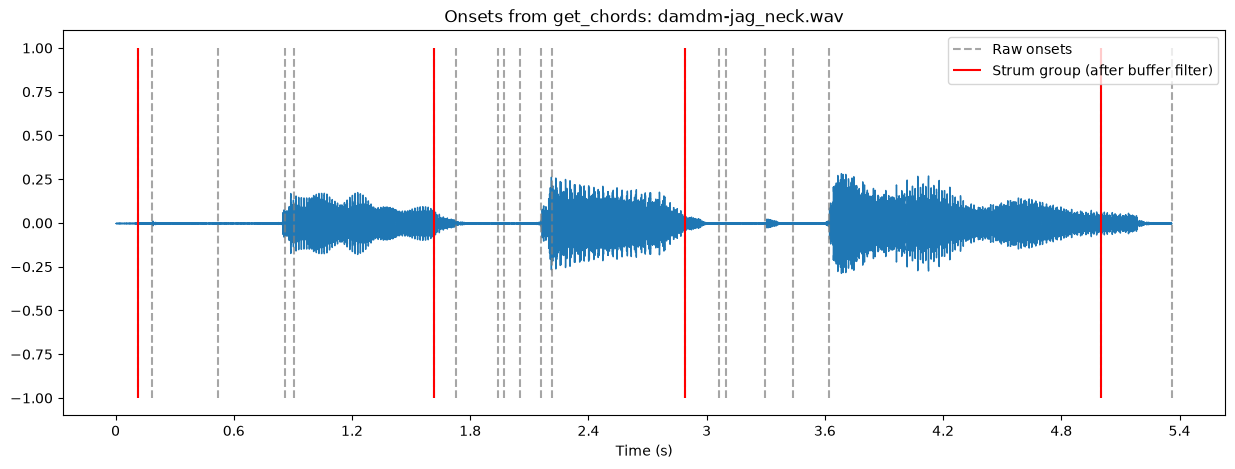

In [21]:
fig, ax = plt.subplots(figsize=(15, 5))
librosa.display.waveshow(clip, sr=sr, ax=ax)

ax.vlines(raw_times, -1, 1, color="grey", linestyle="--", alpha=0.7, label="Raw onsets")
ax.vlines(strum_times, -1, 1, color="red", linestyle="-", label="Strum group (after buffer filter)")

ax.set_title("Onsets from get_chords: damdm-jag_neck.wav")
ax.set_xlabel("Time (s)")
ax.legend()
plt.show()

### Analysis

The grey lines are the raw onsets from `onset_detect`, red lines are the onsets left over after the 0.5s buffer filter in `get_chords`

- The clip has three strums, starting at about 0.85s, 2.2s and 3.6s
- None of the red lines are on a strums beginning
- The first onset is always kept, even when it is just noise
- The filter only looks at the gap between onsets. If the gap is more than 0.5s, it keeps the onset. It doesn't check whether the onset is a strum
- The real strums get thrown out when there is another onset less than 0.5s before them
- The line at the very end is the extra frame added with `np.append`

### Issue

The filter relies on the gaps between raw onsets, but the raw onsets include a lot of noise. The onsets I keep need to be at the start of each strum, so the filter needs to look at the audio itself and not just the gaps

This explains the issues that were occuring in the first iteration when using the chord prompt notebook, where additinal chords were being detected 

_________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________________

Because my onset detection has a flaw in detecting the beginning of a chord, I had to research how to find the change in energy. Librosa have a [root-means squared](https://librosa.org/doc/0.10.2/generated/librosa.feature.rms.html) feature, allowing to detect the energy over the course of the audio clip

[Text(0.5, 1.0, 'log Power spectrogram')]

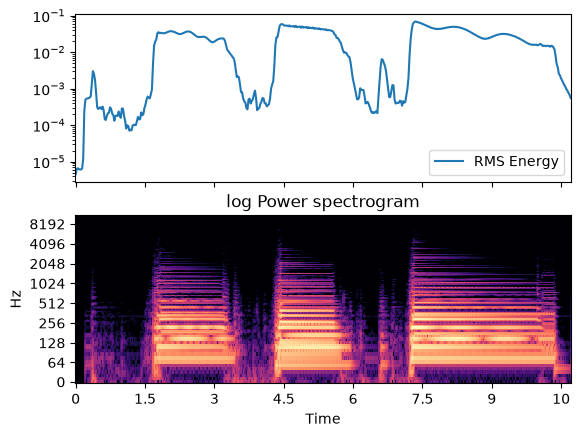

In [29]:
y, sr = librosa.load('../data/clips/sample/damdm-jag_neck.wav', sr=None)
librosa.feature.rms(y=y)
S, phase = librosa.magphase(librosa.stft(y))
rms = librosa.feature.rms(S=S)

fig, ax = plt.subplots(nrows=2, sharex=True)
times = librosa.times_like(rms)

ax[0].semilogy(times, rms[0], label='RMS Energy')
ax[0].set(xticks=[])
ax[0].legend()
ax[0].label_outer()
librosa.display.specshow(librosa.amplitude_to_db(S, ref=np.max),
                         y_axis='log', x_axis='time', ax=ax[1])
ax[1].set(title='log Power spectrogram')